## Setup

In [17]:
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [18]:
%pip install --upgrade -q botocore boto3

Note: you may need to restart the kernel to use updated packages.


In [19]:
import boto3

In [20]:
sess = boto3.Session(profile_name='rasripa+vs-poc-Admin')
bedrock = sess.client('bedrock', 'us-west-2')
response = bedrock.list_foundation_models()
print(response.get('modelSummaries')) 

[{'modelArn': 'arn:aws:bedrock:us-west-2::foundation-model/amazon.titan-tg1-large', 'modelId': 'amazon.titan-tg1-large', 'modelName': 'Titan Text Large', 'providerName': 'Amazon', 'inputModalities': ['TEXT'], 'outputModalities': ['TEXT'], 'responseStreamingSupported': True, 'customizationsSupported': [], 'inferenceTypesSupported': ['ON_DEMAND'], 'modelLifecycle': {'status': 'ACTIVE'}}, {'modelArn': 'arn:aws:bedrock:us-west-2::foundation-model/amazon.titan-embed-g1-text-02', 'modelId': 'amazon.titan-embed-g1-text-02', 'modelName': 'Titan Text Embeddings v2', 'providerName': 'Amazon', 'inputModalities': ['TEXT'], 'outputModalities': ['EMBEDDING'], 'customizationsSupported': [], 'inferenceTypesSupported': ['ON_DEMAND'], 'modelLifecycle': {'status': 'ACTIVE'}}, {'modelArn': 'arn:aws:bedrock:us-west-2::foundation-model/amazon.titan-text-lite-v1:0:4k', 'modelId': 'amazon.titan-text-lite-v1:0:4k', 'modelName': 'Titan Text G1 - Lite', 'providerName': 'Amazon', 'inputModalities': ['TEXT'], 'out

In [21]:
bedrock = sess.client('bedrock-runtime', 'us-west-2')

In [22]:
s3 = sess.resource('s3')

In [23]:
def initialise_bedrock():
    global bedrock
    if bedrock is None:
        sess = boto3.Session(profile_name='rasripa+vs-poc-Admin')
        bedrock = sess.client('bedrock-runtime', 'us-west-2')

In [24]:
def initialise_s3():
    global s3
    if s3 is None:
        sess = boto3.Session(profile_name='rasripa+vs-poc-Admin')
        s3 = sess.resource('s3')

In [25]:
%pip install -q opensearch-py

Note: you may need to restart the kernel to use updated packages.


In [26]:
from opensearchpy import OpenSearch, Urllib3HttpConnection, Urllib3AWSV4SignerAuth, RequestsHttpConnection, RequestsAWSV4SignerAuth

In [27]:
host = 'lni6h2aj69hjm9gyhufc.us-west-2.aoss.amazonaws.com'
region = 'us-west-2'
service = 'aoss'
credentials = sess.get_credentials()
auth = Urllib3AWSV4SignerAuth(credentials, region, service)

In [28]:
opensearch_client = OpenSearch(
            hosts = [{'host': host, 'port': 443}],
            http_auth = auth,
            use_ssl = True,
            verify_certs = True,
            connection_class = Urllib3HttpConnection,
            )

In [29]:
def initialise_opensearch():
    global opensearch_client
    if opensearch_client is None:
        sess = boto3.Session(profile_name='rasripa+vs-poc-Admin')
        host = 'lni6h2aj69hjm9gyhufc.us-west-2.aoss.amazonaws.com'
        region = 'us-west-2'
        service = 'aoss'
        credentials = sess.get_credentials()
        auth = Urllib3AWSV4SignerAuth(credentials, region, service)
        opensearch_client = OpenSearch(
            hosts = [{'host': host, 'port': 443}],
            http_auth = auth,
            use_ssl = True,
            verify_certs = True,
            connection_class = Urllib3HttpConnection,
            )

## Get products into dynamodb

In [ ]:
!aws s3 cp --profile  s3://transferbucket-89719/FlipkartProd/flipkart_com-ecommerce_sample.csv .

In [ ]:
%pip install --quiet tqdm

In [ ]:
import csv
import json
from decimal import Decimal
from tqdm import tqdm
import boto3
from boto3.dynamodb.types import TypeSerializer

In [ ]:
#Initialize the DynamoDB resource
dynamodb = sess.resource('dynamodb')

In [ ]:
def is_json(value):
    try:
        json.loads(value)
        return True
    except:
        return False

In [ ]:
def extract_lists(row, column):
    list_string = row.get(column, "").strip('[]').strip('"')
    if column == "product_category_tree":
        return [cat.strip() for cat in list_string.split(">>")]
    else:
        return [url.strip() for url in list_string.split(",")]

In [ ]:
def simplify_product_specification(product_spec_json):
    simplified_json = {}
    for item in product_spec_json.get('product_specification', []):
        key = item.get('key', None)
        value = item.get('value', None)
        if key and value:
            simplified_json[key] = value
    return simplified_json

In [ ]:


serializer = TypeSerializer()

def convert_to_dynamodb_format_enhanced(value, column=None):
    if column == "product_specifications":
        try:
            # Replace "=>" with ":" to make it a valid Python object
            corrected_value = value.replace("=>", ":")
            # Use ast.literal_eval to convert the string to a Python object
            python_object = json.loads(corrected_value)
            # Serialize the Python object to DynamoDB format
            return serializer.serialize(simplify_product_specification(python_object))
        except Exception as e:
            # If conversion fails, store it as a string
            return {"S": value.strip('"')}
    if column and 'price' in column:
        # Convert the price to a float
        if value.strip():
            return serializer.serialize(Decimal(str(value)))
        else:
            return {"NULL": True}
    else:
        # Serialize other columns using the TypeSerializer
        return serializer.serialize(value.strip('"'))

In [ ]:
# Function to assign parent IDs to the category items in the adjacency list
def assign_parent_ids(adjacency_list_items):
    parent_child_dict = {}
    
    for item in adjacency_list_items:
        category_id = item['PutRequest']['Item']['category_id']['S']
        parent_id = item['PutRequest']['Item']['parent_id']['S']
        
        if parent_id == "TBD":
            parent_id = parent_child_dict.get(category_id, "null")
            item['PutRequest']['Item']['parent_id']['S'] = parent_id
            
# Updated function to convert CSV to DynamoDB compatible JSON using Adjacency List for category trees
def csv_to_dynamodb_json_with_adjacency_list(csv_file_path, json_file_path):
    parent_child_dict = {}  # To store parent-child relationships
    dynamodb_items = []  # For storing product items
    adjacency_list_items = []  # For storing category items
    
    with open(csv_file_path, 'r') as csv_file:
        csv_reader = csv.DictReader(csv_file)
        
        for row in csv_reader:
            dynamodb_item = {}
            categories = extract_lists(row, "product_category_tree")
            images = extract_lists(row, "image")
            
            # Update parent-child relationships
            for i, category in enumerate(categories):
                parent = categories[i - 1] if i > 0 else "null"
                parent_child_dict[category] = parent
            
            for column, value in row.items():
                if column == "product_category_tree":
                    dynamodb_item[column] = {"L": [convert_to_dynamodb_format_enhanced(cat) 
                                                   for cat in categories]}
                elif column == "image":
                    dynamodb_item[column] = {"L": [convert_to_dynamodb_format_enhanced(img) for img in images]}
                elif column == "uniq_id":
                    dynamodb_item['id'] = convert_to_dynamodb_format_enhanced(value, column)
                else:
                    dynamodb_item[column] = convert_to_dynamodb_format_enhanced(value, column)
                    
            dynamodb_items.append({"PutRequest": {"Item": dynamodb_item}})
    
    # Generate the adjacency list items
    for category, parent in parent_child_dict.items():
        adjacency_list_items.append({
            "PutRequest": {
                "Item": {
                    "category_id": {"S": category},
                    "parent_id": {"S": parent}
                }
            }
        })
    
    # Assign parent IDs
    assign_parent_ids(adjacency_list_items)
    
    with open(json_file_path, 'w') as json_file:
        json.dump({
            "ProductTable": {"Items": dynamodb_items},
            "CategoryTable": {"Items": adjacency_list_items}
        }, json_file, indent=4)

In [ ]:
csv_to_dynamodb_json_with_adjacency_list("flipkart_com-ecommerce_sample.csv", "flipkart_com-ecommerce_sample.json")

In [ ]:
 

# Create 'ProductTable'
product_table = dynamodb.create_table(
    TableName='ProductTable',
    KeySchema=[
        {'AttributeName': 'id', 'KeyType': 'HASH'}
    ],
    AttributeDefinitions=[
        {'AttributeName': 'id', 'AttributeType': 'S'}
    ],
    ProvisionedThroughput={
        'ReadCapacityUnits': 25,
        'WriteCapacityUnits': 25
    }
)

# Create 'CategoryTable'
category_table = dynamodb.create_table(
    TableName='CategoryTable',
    KeySchema=[
        {'AttributeName': 'category_id', 'KeyType': 'HASH'}
    ],
    AttributeDefinitions=[
        {'AttributeName': 'category_id', 'AttributeType': 'S'}
    ],
    ProvisionedThroughput={
        'ReadCapacityUnits': 25,
        'WriteCapacityUnits': 25
    }
)

# Wait for tables to be created
product_table.meta.client.get_waiter('table_exists').wait(TableName='ProductTable')
category_table.meta.client.get_waiter('table_exists').wait(TableName='CategoryTable')


In [ ]:

def batch_write_chunks(table_name, table_data):
    dynamodb = sess.client('dynamodb')
    chunk_size = 25  # DynamoDB batch write limit
    
    # Extract the list of items wrapped in 'PutRequest'
    items_list = table_data.get('Items', [])
    
    for i in tqdm(range(0, 2000 if table_name=='ProductTable' else (int(len(items_list))), chunk_size)):
        chunk = items_list[i:i + chunk_size]
        request = {
            table_name: chunk
        }
        dynamodb.batch_write_item(RequestItems=request)

# Load JSON data from the file
with open('flipkart_com-ecommerce_sample.json', 'r') as f:
    data = json.load(f)

# Batch write items to 'ProductTable'
if 'ProductTable' in data:
    batch_write_chunks('ProductTable', data['ProductTable'])

# Batch write items to 'CategoryTable'
if 'CategoryTable' in data:
    batch_write_chunks('CategoryTable', data['CategoryTable'])


## Get records

In [30]:
dynamodb = sess.resource('dynamodb')
table = dynamodb.Table('ProductTable')

lastEvaluatedKey = None
items = [] # Result Array

while True:
    if lastEvaluatedKey == None:
        response = table.scan() 
    else:
        response = table.scan(
        ExclusiveStartKey=lastEvaluatedKey
    )

    items.extend(response['Items'])

    if 'LastEvaluatedKey' in response:
        lastEvaluatedKey = response['LastEvaluatedKey']
    else:
        break

print(len(items))

2000


## Put images in S3 to avoid overloading original server

In [ ]:
%%bash

tablename='ProductTable'
lastevalkey=''
profile=''
> urls.txt

while : ; do
    if [[ -z $lastevalkey ]]; then
        response=$(aws dynamodb scan --profile $profile --table-name $tablename --projection-expression "image" --output json)
    else
        response=$(aws dynamodb scan --profile $profile--table-name $tablename --projection-expression "image" --exclusive-start-key $lastevalkey --output json)
    fi
    
    echo "$response" | jq -r '.Items[] | .image[]' >> urls.txt
    
    lastevalkey=$(echo "$response" | jq -r '.LastEvaluatedKey')
    if [[ $lastevalkey == null ]]; then
        break
    fi
done


In [ ]:
import json
import boto3
from urllib.parse import urlparse
import requests

# AWS Configuration
s3Session = boto3.Session(profile_name='')
s3 = s3Session.client('s3')
bucket_name = "flip-kart-images-rasripa-2023"

def upload_to_s3(url):
    parsed_url = urlparse(url)
    s3_path = parsed_url.path.lstrip('/').replace('img[0-9]a.flixcart.com', 'image', 1)
    response = requests.get(url, stream=True)
    if response.status_code == 200:
        s3.upload_fileobj(response.raw, bucket_name, s3_path)
        print(f'Successfully uploaded {url} to s3://{bucket_name}/{s3_path}')
    else:
        print(f'Failed to retrieve {url}. HTTP Status Code: {response.status_code}')

def read_and_upload(file_path):
    accumulated_lines = ""
    with open(file_path, 'r') as file:
        for line in file:
            accumulated_lines += line.strip()
            try:
                items = json.loads(accumulated_lines)
                for item in items:
                    url = item.get('S', '')
                    if url:
                        upload_to_s3(url)
                # Clear accumulated lines if successful
                accumulated_lines = ""
            except json.JSONDecodeError:
                # Accumulate lines until a complete JSON array is formed
                continue

# Run the function
read_and_upload('urls.txt')


## Set up product desc generation

In [31]:
from decimal import Decimal
from typing import Union, Dict, Any

def json_to_dict(json_input: Union[Dict[str, Any], str]) -> Dict[str, Any]:
    if isinstance(json_input, dict):
        return json_input
    elif isinstance(json_input, str):
        try:
            return json.loads(json_input.replace("=>", ":"))
        except json.JSONDecodeError:
            return {}
    else:
        return {}

def format_decimal(decimal_value: Union[Decimal, str, int]) -> str:
    return str(decimal_value)

def array_to_string(array: list) -> str:
    return ' > '.join(array)

def generate_prompt(product_data: Dict[str, Any]) -> str:
    description = product_data.get('description', '')
    discounted_price = format_decimal(product_data.get('discounted_price', ''))
    retail_price = format_decimal(product_data.get('retail_price', ''))
    product_name = product_data.get('product_name', '')
    product_category_tree = array_to_string(product_data.get('product_category_tree', []))
    product_specifications = json_to_dict(product_data.get('product_specifications', {}))

    template = (
        f"Given the following product details:\n"
        f"- Product ID: {product_data.get('id', '')}\n"
        f"- Brand: {product_data.get('brand', '')}\n"
        f"- Original Description: {description}\n"
        f"- Discounted Price: {discounted_price}\n"
        f"- Retail Price: {retail_price}\n"
        f"- Product Name: {product_name}\n"
        f"- Product Category: {product_category_tree}\n"
        f"- Product Specifications: {product_specifications.get('product_specification', '')}\n\n"
        f"Please generate an enhanced product description that incorporates all the above elements while ensuring "
        f"high-quality language and factual coherence. Make the description rich in relevant details "
        f"and present it in a format that includes:\n"
        f"- A compelling opening sentence\n"
        f"- Key features\n"
        f"- Benefits\n"
        f"- Usage instructions\n"
    )
    return template


test = generate_prompt(items[13]) 


In [32]:
test

"Given the following product details:\n- Product ID: 1adc62302d19c52dc67da80dc5afe2c0\n- Brand: D'clair\n- Original Description: Key Features of D'clair Huwai Honor 4X Battery Charger Dual USB Compatible Compact Durable,D'clair Huwai Honor 4X Battery Charger (Black) Price: Rs. 400 DUAL USB Car Charger Easy and convenient way to charger the phone battery in a vehicle, for operation, safety, care and maintenance, see phone's user guide. Bilitong enhancements enable the best possible operation of your mobile phone. Please check the compatibility of your mobile phone and this enhancement with your dealer. Performance Illustration: Input: DC 12V-24V Output: DC 5V/2.1A Dual Channel Keeping high output Support fast charging Dual USB Can work simultaneously High efficiency IC inside to control the circuit Multi set to protect the circuit Brief fashion design,Specifications of D'clair Huwai Honor 4X Battery Charger (Black) In The Box Sales Package Car Charger General Brand D'clair Model Huwai H

In [33]:
%pip install backoff

Note: you may need to restart the kernel to use updated packages.


In [34]:
import backoff

def backoff_hdlr(details):
    """Handler from https://pypi.org/project/backoff/"""
    print(
        "Backing off {wait:0.1f} seconds after {tries} tries "
        "calling function {target} with kwargs "
        "{kwargs}".format(**details)
    )

In [35]:
from botocore.exceptions import ClientError
import random
import json

@backoff.on_exception(
        backoff.expo,
        (ClientError),
        max_time=random.randint(500, 1000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ThrottlingException' not in str(e) and 'ReadTimeoutError' not in str(e)
    ) 
def generate_description(product_data: dict) -> str:
    generated_description = product_data.get('generated_description')
    if generated_description and 'Sorry' not in generated_description and len(generated_description) > 0:
        return generated_description
    prompt = generate_prompt(product_data)
    claude_prompt = f"\n\nHuman:{prompt}\n\nAssistant:"
    body = json.dumps({"prompt": claude_prompt,"max_tokens_to_sample":2000,
                       "temperature":0,"top_p":1,"stop_sequences": ["\n\nHuman:"],"top_k": 250})
    modelId = 'anthropic.claude-v2'
    accept = 'application/json'
    contentType = 'application/json'
    response = bedrock.invoke_model(body=body, modelId=modelId, accept=accept,
                                    contentType=contentType)
    response_body = json.loads(response.get('body').read())
    if 'Sorry' in response_body.get('completion'):
        print(f'No description found for product:{product_data["description"]}')
        return ''
    #remove first line from response using \n
    return ' '.join(response_body.get('completion').split('\n',2)[2:])

In [36]:
print(generate_description(items[450]))

Add regal flair to your traditional outfits with the Vidhya Kangan Brass Jewel Set. This exquisite jewelry set by Vidhya Kangan features a beautifully crafted necklace and pair of matching earrings made from premium brass. 

The necklace showcases an intricate floral motif pendant flanked by gleaming beads and chains. Complementing it are a gorgeous pair of brass jhumka earrings that make a striking statement. These lightweight jewels are easy to wear and perfect for both everyday and festive occasions. 

Crafted using specialized metalwork techniques, the Vidhya Kangan Brass Jewel Set lends an authentic ethnic vibe to your look. The brass construction ensures durability and long-lasting shine. 

Valued at Rs. 1600, you can now buy this jewelry set for just Rs. 800 on Flipkart. Grab this deal to get 50% off on a high-quality product with a 30-day replacement guarantee. Order now and get free shipping plus cash on delivery for a completely risk-free purchase.

Elevate your style afforda

## Set up content retrieval

In [37]:
def get_id(product_data: dict) -> str:
    return product_data.get('id', '')

In [38]:
def get_image_url_list(product_data: dict) -> list:
    return product_data.get('image', [])

## Set up embedding retrieval

In [39]:
%pip install Pillow

Note: you may need to restart the kernel to use updated packages.


In [40]:
from PIL import Image
from io import BytesIO

def image_to_byte_array(image: Image.Image) -> bytearray:
    byte_io = BytesIO()
    image.save(byte_io, format='WEBP')
    return byte_io.getvalue()

In [41]:
import requests
import json
from urllib.parse import urlparse
import requests
from botocore.exceptions import ClientError
import base64




def fetch_image(url):
    bucket_name = "flip-kart-images-rasripa-2023"
    parsed_url = urlparse(url)
    s3_path = parsed_url.path.lstrip('/').replace('img[0-9]a.flixcart.com', 'image', 1)
    obj = s3.Object(bucket_name, s3_path)
    try:
        return base64.b64encode(obj.get()['Body'].read()).decode(),True
    except Exception as e:
        return None,False


In [42]:

import numpy as np

In [43]:
def fetch_or_byte(image_info):
    return bytearray(requests.get(image_info).content) if isinstance(image_info, str) else image_info

In [44]:
def fetch_or_base64_string(image_info):
    if isinstance(image_info, str):
        image_content = requests.get(image_info).content
    else:
        image_content = image_info
    
    base64_encoded_string = base64.b64encode(image_content).decode()
    
    return base64_encoded_string

In [45]:

@backoff.on_exception(
        backoff.expo,
        (ClientError),
        max_time=random.randint(500, 1000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ThrottlingException' not in str(e) and 'ReadTimeoutError' not in str(e)
    ) 
def get_image_embedding(base64_image_string, bedrock):
    modelId = "amazon.titan-embed-image-v1"
    contentType = "application/json"
    accept = "application/json"
    body = json.dumps({"inputImage": base64_image_string})
    response = bedrock.invoke_model(body=body, modelId=modelId, accept=accept,contentType=contentType)
    return json.loads(response.get('body').read())['embedding']

In [46]:
%pip install -q langchain

Note: you may need to restart the kernel to use updated packages.


In [47]:
from langchain.text_splitter import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 750,
    chunk_overlap  = 100,
    length_function = len,
    is_separator_regex = False,
)

In [48]:
@backoff.on_exception(
        backoff.expo,
        (ClientError),
        max_time=random.randint(500, 1000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ThrottlingException' not in str(e) and 'ReadTimeoutError' not in str(e)
    ) 
def get_text_embedding(text_chunks, bedrock):

    embeddings = []

    modelId="amazon.titan-embed-image-v1"
    contentType = "application/json"
    accept = "application/json"

    for chunk in text_chunks:
        body = json.dumps({"inputText": chunk})

        response = bedrock.invoke_model(body=body, modelId=modelId, accept=accept, contentType=contentType)

        chunk_embedding = json.loads(response.get('body').read())['embedding']
        embeddings.append(chunk_embedding)

    aggregated_embedding = aggregate_embeddings(embeddings)

    return aggregated_embedding

def aggregate_embeddings(embeddings):
    averaged_embedding = [sum(x)/len(embeddings) for x in zip(*embeddings)]
    return averaged_embedding

In [49]:
@backoff.on_exception(
        backoff.expo,
        (ClientError),
        max_time=random.randint(500, 1000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ThrottlingException' not in str(e) and 'ReadTimeoutError' not in str(e)
    ) 
def get_multi_embedding(image_data, text_chunks, bedrock):

    embeddings = []

    modelId="amazon.titan-embed-image-v1"
    contentType = "application/json"
    accept = "application/json"

    for chunk in text_chunks:
        body = json.dumps({"inputText": chunk,
                           "inputImage": image_data})

        response = bedrock.invoke_model(body=body, modelId=modelId, accept=accept, contentType=contentType)

        chunk_embedding = json.loads(response.get('body').read())['embedding']
        embeddings.append(chunk_embedding)

    aggregated_embedding = aggregate_embeddings(embeddings)

    return aggregated_embedding

def aggregate_embeddings(embeddings):
    averaged_embedding = [sum(x)/len(embeddings) for x in zip(*embeddings)]
    return averaged_embedding

## Opensearch

In [50]:
'''class TextEmbedding(Document):
    vector_embedding = FloatVector() 

    class Index:
        name = 'vs-text-embeddings-index'

    def save(self, ** kwargs):
        return super(TextEmbedding, self).save(** kwargs)'''

"class TextEmbedding(Document):\n    vector_embedding = FloatVector() \n\n    class Index:\n        name = 'vs-text-embeddings-index'\n\n    def save(self, ** kwargs):\n        return super(TextEmbedding, self).save(** kwargs)"

In [51]:
'''class ImageEmbedding(Document):
    title = Text(fields={'raw': Keyword()})
    director = Text()
    year = Text()

    class Index:
        name = 'vs-text-embeddings-index'

    def save(self, ** kwargs):
        return super(TextEmbedding, self).save(** kwargs)'''

"class ImageEmbedding(Document):\n    title = Text(fields={'raw': Keyword()})\n    director = Text()\n    year = Text()\n\n    class Index:\n        name = 'vs-text-embeddings-index'\n\n    def save(self, ** kwargs):\n        return super(TextEmbedding, self).save(** kwargs)"

## Create and populate vector stores

### Helpers

In [52]:
%pip install --upgrade faiss-cpu --quiet

Note: you may need to restart the kernel to use updated packages.


In [53]:
import faiss

d = 1024
quantizer = faiss.IndexFlatL2(d)
try:
    bedrocktext_index = faiss.read_index("bedrocktext.index")
    print("bedrocktext_index loaded")
    print(bedrocktext_index.ntotal)
except Exception as e:
    bedrocktext_index = faiss.IndexIVFFlat(quantizer, d, 10)
    print("bedrocktext_index created")

bedrocktext_index loaded
1738


In [54]:
try:
    bedrockimage_index = faiss.read_index("bedrockimage.index")
    print("bedrock image index loaded")
    print(bedrockimage_index.ntotal)
except Exception as e:
    bedrockimage_index = faiss.IndexIVFFlat(quantizer, d, 10)
    print("bedrock image index created")

bedrock image index loaded
6364


In [55]:
try:
    bedrockmulti_index = faiss.read_index("bedrockmulti.index")
    print("bedrock multi index loaded")
    print(bedrockmulti_index.ntotal)
except Exception as e:
    bedrockmulti_index = faiss.IndexIVFFlat(quantizer, d, 10)
    print("bedrock multi index created")

bedrock multi index loaded
6231


In [56]:
def normalise_embedding(embedding):
    return embedding / np.linalg.norm(embedding)

In [57]:
import re
import unicodedata

def clean_and_prepare_text(text):
    # Normalize extra whitespace to single space
    text = re.sub(r'\s+', ' ', text).strip()
    
    # Remove special characters
    text = re.sub(r'[^\w\s]', '', text)
    
    # Unicode normalization
    text = unicodedata.normalize('NFKD', text)
    
    # Lowercasing
    text = text.lower()
    
    #text = text[:320]

    return text


In [58]:
def split_data(data, num_splits):
    avg = len(data) // num_splits
    out = []
    last = 0.0

    while last < len(data):
        out.append(data[int(last):int(last + avg)])
        last += avg

    return out


In [59]:
def process_item(item):
    return get_id(item), get_image_url_list(item), generate_description(item)

In [60]:
item_id, image_url_list, description = process_item(items[150])
sanitised_description = clean_and_prepare_text(description)
image_response = fetch_image(image_url_list[0])
image_content = image_response[0]

In [61]:
image_embedding = normalise_embedding(np.array(get_image_embedding(image_content,bedrock)))
image_embedding

array([ 0.02490927, -0.00078986,  0.01318726, ..., -0.0121799 ,
       -0.00370892,  0.0243598 ])

In [62]:
multi_embedding = np.array(get_multi_embedding(image_content,text_splitter.split_text(sanitised_description),bedrock))
multi_embedding

array([ 0.02673686, -0.0014249 ,  0.01959412, ..., -0.00127747,
       -0.00719122,  0.02505832])

In [63]:
text_embedding = np.array(get_text_embedding(text_splitter.split_text(sanitised_description),bedrock))
text_embedding

array([ 0.02856445, -0.00205994,  0.02600098, ...,  0.00962496,
       -0.01067352,  0.02575684])

### Populate OpenSearch

In [64]:
initialise_opensearch()

##### Create ingest pipeline

In [ ]:
connector_body = {
  "name": "Amazon Bedrock Connector: embedding",
  "description": "The connector to bedrock Titan multimodal embedding model",
  "version": 1,
  "protocol": "aws_sigv4",
  "parameters": {
    "region": "us-west-2",
    "service_name": "bedrock"
  },
  "credential": {
    "roleArn": "arn:aws:iam::669775656565:role/opensearch-ingestion-bedrock-role"
  },
  "actions": [
    {
      "action_type": "predict",
      "method": "POST",
      "url": "https://bedrock-runtime.us-east-1.amazonaws.com/model/amazon.titan-embed-image-v1/invoke",
      "headers": {
        "content-type": "application/json",
        "x-amz-content-sha256": "required"
      },
      "request_body": "{ \"inputImage\": \"${parameters.inputImage}\" }",
      "pre_process_function": "\n    StringBuilder builder = new StringBuilder();\n    builder.append(\"\\\"\");\n    String first = params.text_docs[0];\n    builder.append(first);\n    builder.append(\"\\\"\");\n    def parameters = \"{\" +\"\\\"inputText\\\":\" + builder + \"}\";\n    return  \"{\" +\"\\\"parameters\\\":\" + parameters + \"}\";",
      "post_process_function": "\n      def name = \"sentence_embedding\";\n      def dataType = \"FLOAT32\";\n      if (params.embedding == null || params.embedding.length == 0) {\n        return params.message;\n      }\n      def shape = [params.embedding.length];\n      def json = \"{\" +\n                 \"\\\"name\\\":\\\"\" + name + \"\\\",\" +\n                 \"\\\"data_type\\\":\\\"\" + dataType + \"\\\",\" +\n                 \"\\\"shape\\\":\" + shape + \",\" +\n                 \"\\\"data\\\":\" + params.embedding +\n                 \"}\";\n      return json;\n    "
    }
  ]
}

In [ ]:
opensearch_client.http.get("/")

In [ ]:
#create connector
opensearch_client.http.post(url="/_plugins/_ml/connectors/_create", body=connector_body)

In [ ]:
pipeline_body = {
  "description": "An image embedding pipeline",
  "processors": [
    {
      "text_image_embedding": {
        "model_id": "amazon.titan-embed-image-v1",
        "embedding": "vector_embedding",
        "field_map": {
          "image": "image_binary"
        }
      }
    }
  ]
}

In [ ]:
opensearch_client.ingest.put_pipeline(
    id='image_embedding_pipeline',
    body=pipeline_body)

#### Create indices

##### HNSW Indices

In [49]:
hnsw_index_body={
  "settings": {
    "index": {
      "knn": True,
      "knn.algo_param.ef_search": 512
    }
  },
  "mappings": {
    "properties": {
      "embedding": {
        "type": "knn_vector",
        "dimension": 1024,
        "method": {
          "name": "hnsw",
          "engine": "nmslib",
          "space_type": "cosinesimil",
          "parameters": {
            "ef_construction": 512,
            "m": 16
          }
        }
      },
      "prodId": {
        "type": "text"
      }
    }
  }
}


In [50]:
hnsw_indices = [
    "test_hnsw_multi_index","test_hnsw_image_index","test_hnsw_text_index"
]

In [51]:
for index in hnsw_indices:
    try:
        opensearch_client.indices.delete(index)
    except Exception as e:
        print(e)

In [52]:
for index in hnsw_indices:
    try:
        opensearch_client.indices.create(index, body=json.dumps(hnsw_index_body))
    except Exception as e:
        print(e)

NotFoundError(404, 'index_not_found_exception', 'no such index [sqakjowBmcypDwgxmWTK]')
NotFoundError(404, 'index_not_found_exception', 'no such index [tKakjowBmcypDwgxnGT6]')


##### IVF Indices

In [ ]:
train_index_body = {
  "settings": {
    "number_of_shards": 3,
    "number_of_replicas": 0
  },
  "mappings": {
    "properties": {
      "train-field": {
        "type": "knn_vector",
        "dimension": 1024
      }
    }
  }
}

In [ ]:
opensearch_client.indices.create("train_index", body=json.dumps(train_index_body))

In [ ]:
#opensearch_client.indices.delete("test_image_index")

#### Create actions(docs and operation_type, in this case index doc) for bulk load

In [53]:
def process_records_to_actions_partial(items_chunk):
    initialise_bedrock()
    initialise_s3()
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size = 1400,
        chunk_overlap  = 600,
        length_function = len,
        is_separator_regex = False,
        )
    
    local_actions = []
    
    for item in tqdm(items_chunk):
        product_id, image_url_list, description = process_item(item)
        sanitised_description = clean_and_prepare_text(description)
        text_chunks = text_splitter.split_text(sanitised_description)
        image_embedding_count = 0
        for image in image_url_list:
            image_response = fetch_image(image)
            if not image_response[1]:
                continue
            try:
                image_content = image_response[0]
                
                image_embedding = normalise_embedding(np.array(get_image_embedding(image_content,bedrock)))
                multi_embedding = normalise_embedding(np.array(get_multi_embedding(image_content,text_chunks, bedrock)))
                
                image_action = {
                    "_index": "test_hnsw_image_index",
                    "_source":{
                        "prodId": product_id,
                        "embedding": image_embedding.tolist()
                    }
                }
                
                multi_action = {
                    "_index": "test_hnsw_multi_index",
                    "_source":{
                        "prodId": product_id,
                        "embedding": multi_embedding.tolist()
                    }
                }
                local_actions.append(image_action)
                local_actions.append(multi_action)
                image_embedding_count += 1
            except Exception as e:
                pass

        if image_embedding_count == 0:
            continue

        try:
            text_embedding = normalise_embedding(np.array(get_text_embedding(text_chunks, bedrock)))
            text_action={
                "_index": "test_hnsw_text_index",
                "_source":{
                "prodId": product_id,
                "embedding": text_embedding.tolist()
                }
                }
            local_actions.append(text_action)
            
        except Exception as e:
            continue
        

    return local_actions



In [ ]:
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm


NUM_PROCESSES = 200
items_chunks = split_data(items, NUM_PROCESSES)

with ThreadPoolExecutor(max_workers=NUM_PROCESSES) as executor:
    futures = [executor.submit(process_records_to_actions_partial, chunk) for chunk in tqdm(items_chunks)]


In [55]:
'''# Initialize global arrays
global_image_actions = []
global_text_actions = []
global_multi_actions = []

# Initialize a counter for the global _id, starting from 1
current_global_image_id = 1
current_global_text_id = 1
current_global_multi_id = 1

for future in tqdm(futures):
    local_image_actions, local_text_actions, local_multi_actions = future.result()

    # Update actions with _id using list comprehension and extend global actions lists
    global_image_actions.extend(
        [{**action, '_id': current_global_image_id + i} for i, action in enumerate(local_image_actions)]
    )
    current_global_image_id += len(local_image_actions)

    global_text_actions.extend(
        [{**action, '_id': current_global_text_id + i} for i, action in enumerate(local_text_actions)]
    )
    current_global_text_id += len(local_text_actions)

    global_multi_actions.extend(
        [{**action, '_id': current_global_multi_id + i} for i, action in enumerate(local_multi_actions)]
    )
    current_global_multi_id += len(local_multi_actions)'''

"# Initialize global arrays\nglobal_image_actions = []\nglobal_text_actions = []\nglobal_multi_actions = []\n\n# Initialize a counter for the global _id, starting from 1\ncurrent_global_image_id = 1\ncurrent_global_text_id = 1\ncurrent_global_multi_id = 1\n\nfor future in tqdm(futures):\n    local_image_actions, local_text_actions, local_multi_actions = future.result()\n\n    # Update actions with _id using list comprehension and extend global actions lists\n    global_image_actions.extend(\n        [{**action, '_id': current_global_image_id + i} for i, action in enumerate(local_image_actions)]\n    )\n    current_global_image_id += len(local_image_actions)\n\n    global_text_actions.extend(\n        [{**action, '_id': current_global_text_id + i} for i, action in enumerate(local_text_actions)]\n    )\n    current_global_text_id += len(local_text_actions)\n\n    global_multi_actions.extend(\n        [{**action, '_id': current_global_multi_id + i} for i, action in enumerate(local_multi_a

In [56]:
# Initialize global arrays
global_actions = []

for future in tqdm(futures):
    local_actions = future.result()

    global_actions.extend(local_actions)


100%|██████████| 200/200 [00:00<00:00, 360955.59it/s]


In [57]:
'''global_actions = []
global_actions.extend(global_text_actions)
global_actions.extend(global_image_actions)
global_actions.extend(global_multi_actions)'''

'global_actions = []\nglobal_actions.extend(global_text_actions)\nglobal_actions.extend(global_image_actions)\nglobal_actions.extend(global_multi_actions)'

In [58]:
'''from tqdm import tqdm
def gen_data():
    initialise_bedrock()
    initialise_s3()
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size = 750,
        chunk_overlap  = 100,
        length_function = len,
        is_separator_regex = False,
        )
    
    local_actions = []
    
    for item in tqdm(items):
        product_id, image_url_list, description = process_item(item)
        sanitised_description = clean_and_prepare_text(description)
        text_chunks = text_splitter.split_text(sanitised_description)
        image_embedding_count = 0
        for image in image_url_list:
            image_response = fetch_image(image)
            if not image_response[1]:
                continue
            try:
                image_content = image_response[0]
                
                image_embedding = normalise_embedding(np.array(get_image_embedding(image_content,bedrock)))
                multi_embedding = normalise_embedding(np.array(get_multi_embedding(image_content,text_chunks, bedrock)))
                
                image_action = {
                    "_index": "test_hnsw_image_index",
                    "_source":{
                        "prodId": product_id,
                        "embedding": image_embedding.tolist()
                    }
                }
                
                multi_action = {
                    "_index": "test_hnsw_multi_index",
                    "_source":{
                        "prodId": product_id,
                        "embedding": multi_embedding.tolist()
                    }
                }
                local_actions.append(image_action)
                local_actions.append(multi_action)
                image_embedding_count += 1
            except Exception as e:
                pass

        if image_embedding_count == 0:
            continue

        try:
            text_embedding = normalise_embedding(np.array(get_text_embedding(text_chunks, bedrock)))
            text_action={
                "_index": "test_hnsw_text_index",
                "_source":{
                "prodId": product_id,
                "embedding": text_embedding.tolist()
                }
                }
            local_actions.append(text_action)
            
        except Exception as e:
            continue
        
    
    for action in local_actions:
        yield action'''



'from tqdm import tqdm\ndef gen_data():\n    initialise_bedrock()\n    initialise_s3()\n    text_splitter = RecursiveCharacterTextSplitter(\n        chunk_size = 750,\n        chunk_overlap  = 100,\n        length_function = len,\n        is_separator_regex = False,\n        )\n    \n    local_actions = []\n    \n    for item in tqdm(items):\n        product_id, image_url_list, description = process_item(item)\n        sanitised_description = clean_and_prepare_text(description)\n        text_chunks = text_splitter.split_text(sanitised_description)\n        image_embedding_count = 0\n        for image in image_url_list:\n            image_response = fetch_image(image)\n            if not image_response[1]:\n                continue\n            try:\n                image_content = image_response[0]\n                \n                image_embedding = normalise_embedding(np.array(get_image_embedding(image_content,bedrock)))\n                multi_embedding = normalise_embedding(np.array

In [59]:
from opensearchpy.helpers import parallel_bulk

In [60]:
for success, info in parallel_bulk(client=opensearch_client,actions=global_actions, request_timeout=60*60, thread_count = 8):
    if not success:
        print('A document failed:', info)

#### Search opensearch index

In [65]:
def get_item_from_dynamodb(table_name, item_id):
    
    # Get table
    table = dynamodb.Table(table_name)
    
    try:
        # Fetch item by ID
        response = table.get_item(
            Key={
                'id': item_id
            }
        )
    except ClientError as e:
        print(f"An error occurred: {e.response['Error']['Message']}")
        return None
    
    # Return item if found
    return response.get('Item', None)

In [66]:
from collections import defaultdict

def search_opensearch_indexes(query_image_url, k=5):
    """
    Search for similar images and texts based on the embedding of a query image.
    
    Parameters:
    - query_image_url (str): The URL of the query image.
    - k (int, optional): The number of top similar items to return. Default is 5.
    
    Returns:
    - list: A list of product IDs for the top k similar items.
    
    """
    
    query_image_embedding_array = normalise_embedding(np.array(get_image_embedding(fetch_or_base64_string(query_image_url), bedrock)))
    query_image_embedding = query_image_embedding_array.tolist()
    
    search_query = {
        "query": {
            "knn": {
                "embedding": {
                    "vector": query_image_embedding,
                    "k": k
                }
            }
        }
    }
    
    # Search in opensearch indexes
    image_index_response = opensearch_client.search(index="test_hnsw_image_index", body=search_query)
    text_index_response = opensearch_client.search(index="test_hnsw_text_index", body=search_query)
    multi_index_response = opensearch_client.search(index="test_hnsw_multi_index", body=search_query)
    
    return image_index_response['hits']['hits'], text_index_response['hits']['hits'], multi_index_response['hits']['hits']
    

In [67]:
test = search_opensearch_indexes("http://img5a.flixcart.com/image/pillow/7/u/5/3drfiljdx-6-42x63-jdx-jdx-premium-3d-reliance-fibre-very-soft-1100x1100-imae4a5gxfu3dwzy.jpeg")

In [68]:
len(test[1])

10

In [69]:
def combine_results(image_results, text_results, multi_results, weights, top_n):
    # Aggregate scores
    combined_scores = {}
    for results, weight in zip([image_results, text_results, multi_results], weights):
        for result in results:
            prod_id = result['_source']['prodId']
            combined_scores[prod_id] = combined_scores.get(prod_id, 0) + result['_score'] * weight

    # Sort products by combined score and get top N
    sorted_products = sorted(combined_scores.items(), key=lambda x: x[1], reverse=True)[:top_n]
    return sorted_products


weights = [0.3, 0.2, 0.5]   
top_n = 6                   

top_similar_products = combine_results(test[0], test[1], test[2], weights, top_n)


In [70]:
top_similar_products

[('9ab4a4be795873a249929d00fe26a157', 2.3383148499999997),
 ('727e7fbc1a107334d3175c0edb7062c6', 2.3383148499999997),
 ('d12d8e67f9bb082bbef65372a196821b', 1.29090095),
 ('b702cdd87b12d26bb8c393b82c7f39c7', 1.13690824),
 ('3e6ac7ecc646d1d40cac926e29be483f', 0.848275848),
 ('5bff28a8801678232a38836e6bdacb02', 0.132143926)]

In [71]:
from PIL import Image
import matplotlib.pyplot as plt
import requests
from io import BytesIO

def visual_search(query_image, weights, top_n):
    """
    Visualize the search results along with the query image.
    
    Parameters:
    - query_image (str or bytes): The URL or byte content of the query image.
    - search_results (list): A list of product IDs representing the search results.
    - records (list): A list of records containing product information.
    """
    # Display Query Image
    query_img = Image.open(BytesIO(fetch_or_byte(query_image)))
    
    search_responses = search_opensearch_indexes(query_image, k=5)
    search_results = combine_results(search_responses[0], search_responses[1], search_responses[2], weights, top_n)
    products = []
    
    for product_id,score in search_results:
        item = get_item_from_dynamodb("ProductTable", product_id)
        images=item['image']
        products.append((product_id,images))
    
    plt.figure(figsize=(20, 10))
    plt.subplot(1, len(search_results) + 1, 1)
    plt.imshow(query_img)
    plt.title("Query Image")
    plt.axis('off')
    
    
    
    # Display Search Results
    for i,result in enumerate(products,2):
        response = requests.get(result[1][0])
        img = Image.open(BytesIO(response.content))
        plt.subplot(1, len(search_results) + 1, i)
        plt.imshow(img)
        plt.title(f"ID: {result[0][:8]}")
    
    plt.show()

In [72]:
test_urls = [
    "http://img5a.flixcart.com/image/pillow/7/u/5/3drfiljdx-6-42x63-jdx-jdx-premium-3d-reliance-fibre-very-soft-1100x1100-imae4a5gxfu3dwzy.jpeg",
    "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSaxZ42Sj1gIFgZHYNuKNnioNKvCQQFZHUdbR18JY6Q76RYFYnPzbOGwqVRI_AuNkX3GBU&usqp=CAU",
    "https://m.media-amazon.com/images/I/71S6Ph8y8GL._AC_UY695_.jpg",
    "https://encrypted-tbn3.gstatic.com/shopping?q=tbn:ANd9GcTEJzVGBokOCAhgnFceUDyEUpk9OeO8sh21oCTujgki8RpTDwYnlSeedJ3fTKtFaafg6TYepltQznNXdAItnlV58pHLlEZHo7gRyqsX7raEQmCK3r2jZv1RoYwvUqsP-Y6XDgeqzOY&usqp=CAc",
    "http://img5a.flixcart.com/image/top/d/v/u/1-1-mg2171-mangosteen-m-original-imaec88gr9r9erd8.jpeg"
    ]

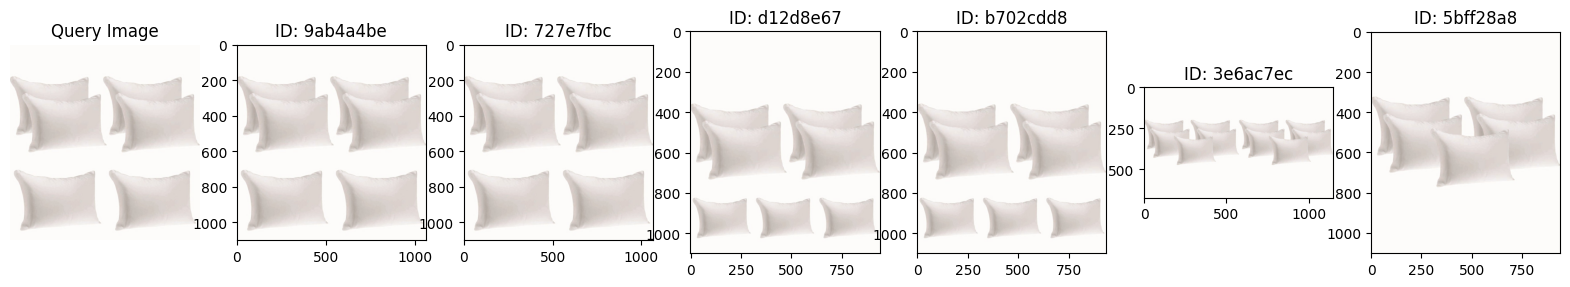

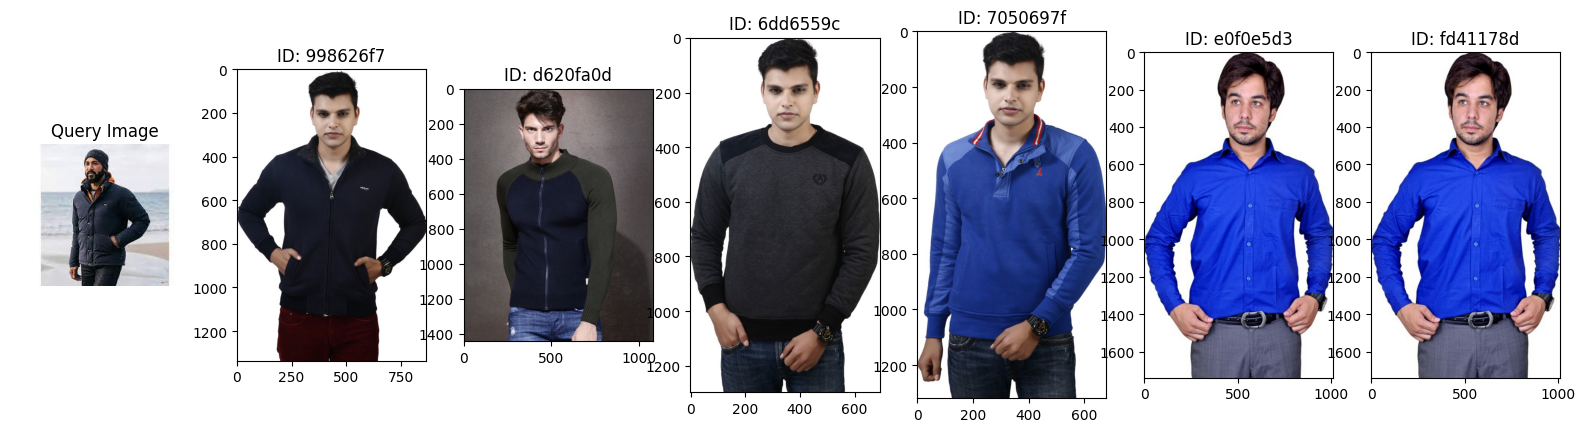

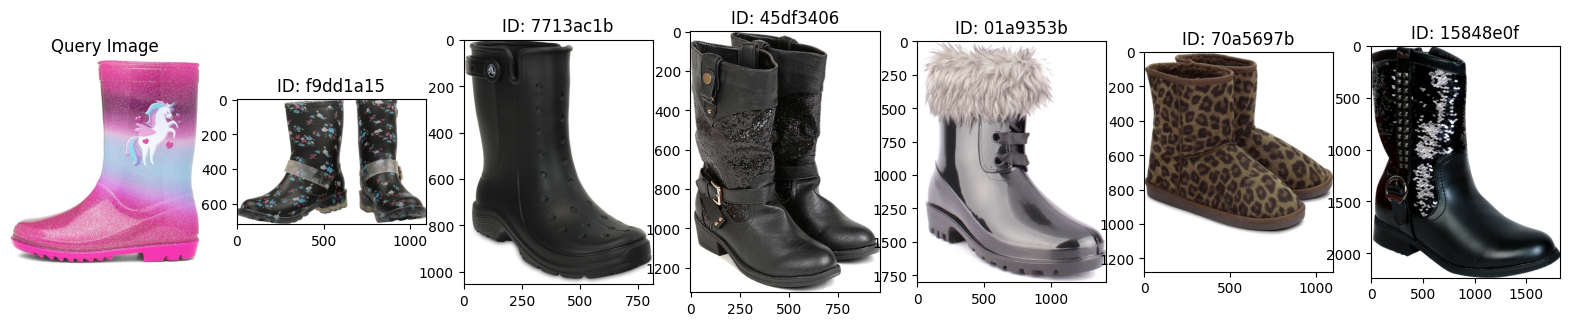

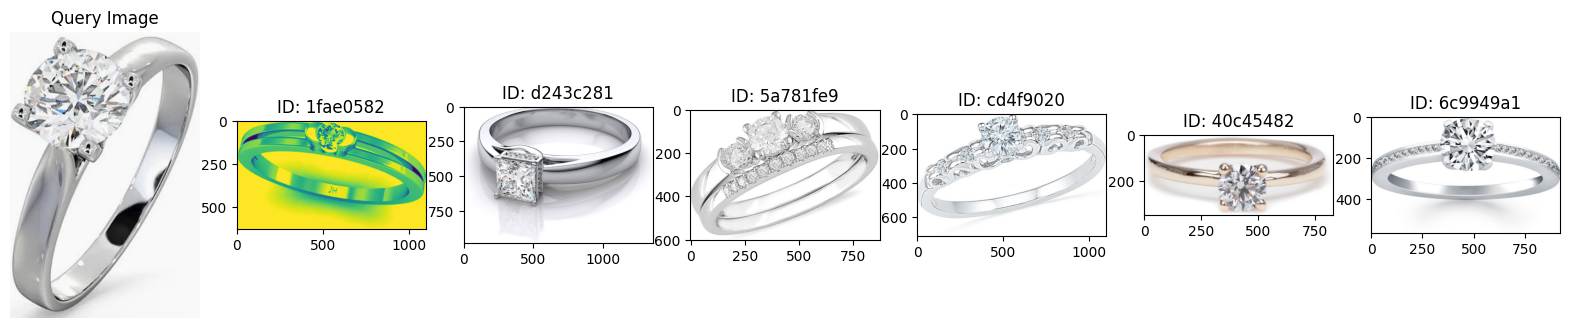

ValidationException: An error occurred (ValidationException) when calling the InvokeModel operation: 400 Bad Request: Image exceeds max pixels allowed. 

In [73]:
for url in test_urls:
    visual_search(url, weights, top_n)

#### Test search api

In [74]:
import requests
import json
import uuid
import base64
from PIL import Image
from io import BytesIO

In [75]:
jobs = {}

In [76]:
api_url = 'https://1iydovg8jf.execute-api.us-west-2.amazonaws.com/dev'

In [77]:
def resize_image(image, width, height):
    Image.MAX_IMAGE_PIXELS = 100000000

    image.thumbnail((width, height))
    return image

In [78]:
import json
import requests
def search_image(uploaded_image):
    jobId = str(uuid.uuid4())
    jobs[jobId] = {'jobStatus': 'init'}
    resizedImage = resize_image(uploaded_image,2048, 2048)
    buffer = BytesIO()
    resizedImage.save(buffer, format=resizedImage.format)
    base64Image = base64.b64encode(buffer.getvalue()).decode('utf-8')
    jobs[jobId]['image'] = base64Image
    payload = {'image': base64Image}
    headers = {'content-type': 'application/json'}
    response = requests.post(f"{api_url}/search", data=json.dumps(payload), headers=headers)
    if response.status_code == 200:
        jobs[jobId].update({'jobStatus': 'Image Uploaded'})
        '''top_results = response.json()['results']
        jobs[jobId].update({'top_results': top_results})
        return (jobId, top_results)'''
        print(response.json())
        return response
    else:
        print(f"Error searching image: {response.status_code}")
   

In [79]:
test_url = "http://img5a.flixcart.com/image/pillow/7/u/5/3drfiljdx-6-42x63-jdx-jdx-premium-3d-reliance-fibre-very-soft-1100x1100-imae4a5gxfu3dwzy.jpeg"

In [80]:
response = requests.get(test_url, stream=True)

In [81]:
image = Image.open(BytesIO(response.content))

In [82]:
results = []
for url in test_urls:
    response = requests.get(url, stream=True)
    image = Image.open(BytesIO(response.content))
    test = search_image(image)
    results.append(test)

{'statusCode': 200, 'body': '{"products": {"ProductTable": [{"product_rating": "No rating available", "discounted_price": 2880, "product_name": "JDX Plain Bed/Sleeping Pillow", "pid": "PLWE6S4AVYSK8KHT", "retail_price": 5899, "brand": "JDX", "product_specifications": {"Machine Washable": "Yes", "Model ID": "MKESPPPIILJDX-6-38x66", "Model Name": "JDX Premium Reliance Fibre VERY Soft Pillow-38x66", "Character": "Comfort Pillow", "Color": "White", "Ideal For": "Men", "Filling Material": "Polyester Fibre", "Pillow Cover Material": "Cotton", "Ideal Usage": "Men", "Brand": "JDX", "Type": "Bed/Sleeping Pillow", "Sales Package": "6 Pillows", "Number of Contents in Sales Package": "6", "Length": "66 cm", "Sweat Absorbent": "Yes", "Hand Washable": "Yes", "With Pillow Cover": "Yes", "Width": "38 cm", "External Material": "Yes"}, "product_url": "http://www.flipkart.com/jdx-plain-bed-sleeping-pillow/p/itme6s4apba92nfa?pid=PLWE6S4AVYSK8KHT", "crawl_timestamp": "2016-01-06 18:20:45 +0000", "image": [

## Clean Up

In [ ]:
%cd ~/vs

In [ ]:
def delete_table(table_name):
    table = dynamodb.Table(table_name)
    table.delete()

In [ ]:
!rm flipkart_com-ecommerce_sample.json
!rm flipkart_com-ecommerce_sample.csv

In [ ]:
delete_table('ProductTable')
delete_table('CategoryTable')